## CNN through the use of Fashion MNST


In [1]:

#Imprts Pytorch which is an AI framework
import torch
import torchvision
from torch import nn

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Using device:", device)

PyTorch version: 2.14.0
Torchvision version: 0.29.0
Using device: mps


In [2]:
#Load Fashion MNST dataset
from torchvision import datasets, transforms
transform = transforms.ToTensor()
train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)
print("Number of training images:", len(train_data))
image, label = train_data[0]
print("Image shape:", image.shape)
print("Label:", label)


100.0%
100.0%
100.0%
100.0%

Number of training images: 60000
Image shape: torch.Size([1, 28, 28])
Label: 9


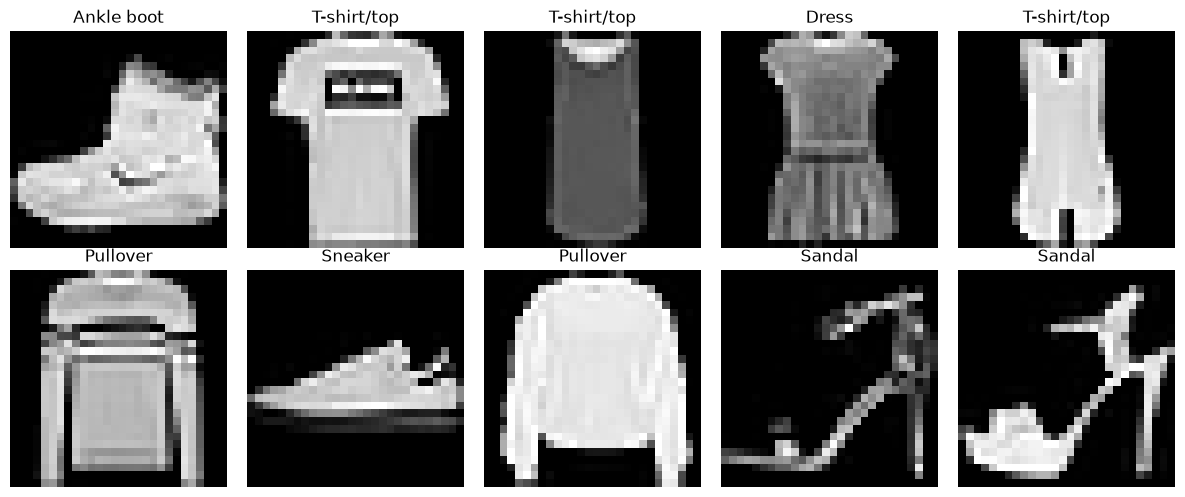

In [4]:
#Improting grpah to visilaize the images
import matplotlib.pyplot as plt
class_names = [
    "T-shirt/top", "Trouser", "Pullover",
    "Dress", "Coat", "Sandal",
    "Shirt", "Sneaker", "Bag", "Ankle boot"
]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
#CNN Netowrk Archietecutre
# Create a convolutional layer
conv_layer = nn.Conv2d(
    in_channels=1,
    out_channels=8,
    kernel_size=3
)
#Basically what is happening the code up above is that there is one channel becuase all the iamges are greyscale if RGB images there there would be thre channels, we are creating. diffrent filters and in each filter we are readnomly assinging 9 weights

# Get the first Fashion-MNIST image
image, label = train_data[0]
# Add a batch dimension
image = image.unsqueeze(0)
# Pass the image through our convolutional layer
output = conv_layer(image)
# Print the shapes
print("Original image shape:", image.shape)
print("Output shape:", output.shape)
# Look at the numbers inside our first filter
print("First filter weights:")
print(conv_layer.weight[0, 0].detach())


Original image shape: torch.Size([1, 1, 28, 28])
Output shape: torch.Size([1, 8, 26, 26])
First filter weights:
tensor([[-0.0432,  0.3041, -0.2663],
        [ 0.0038,  0.2061, -0.2091],
        [-0.0505, -0.0651,  0.2182]])


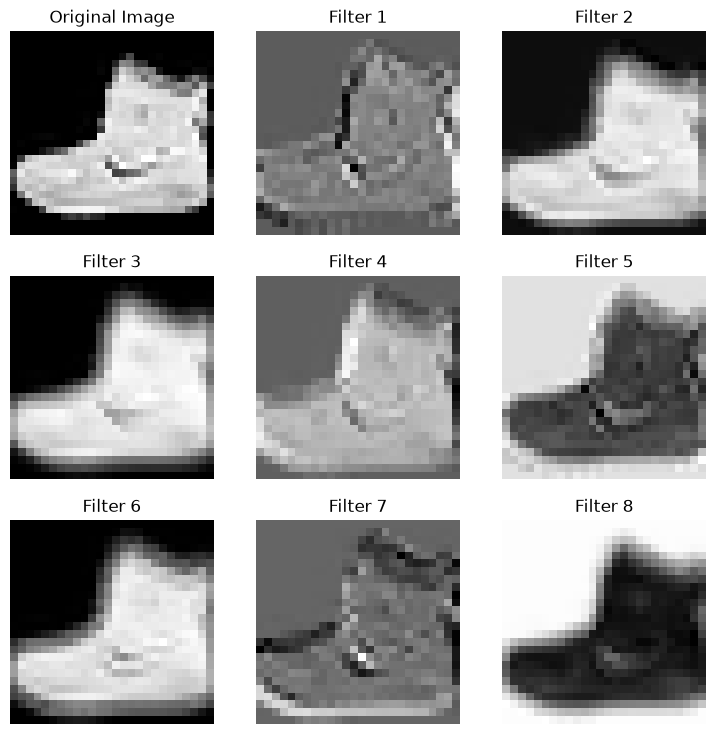

In [6]:
# Get the feature maps from Cell 4
feature_maps = output.detach().cpu()
# Create a 3x3 grid
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
# Display the original image
axes[0, 0].imshow(image[0, 0], cmap="gray")
axes[0, 0].set_title("Original Image")
# Display all 8 feature maps
for i in range(8):
    ax = axes.flat[i + 1]
    ax.imshow(feature_maps[0, i], cmap="gray")
    ax.set_title(f"Filter {i + 1}")
# Remove the axes
for ax in axes.flat:
    ax.axis("off")

In [7]:
# Create ReLU and Max Pooling layers
relu = nn.ReLU()
pool = nn.MaxPool2d(kernel_size=2)
# Apply ReLU to our convolution output
relu_output = relu(output)
# Apply Max Pooling
pooled_output = pool(relu_output)
# Print the dimensions
print("After Convolution:", output.shape)
print("After ReLU:", relu_output.shape)
print("After Max Pooling:", pooled_output.shape)

After Convolution: torch.Size([1, 8, 26, 26])
After ReLU: torch.Size([1, 8, 26, 26])
After Max Pooling: torch.Size([1, 8, 13, 13])


In [8]:
# Create flatten and linear layers
flatten = nn.Flatten()
classifier = nn.Linear(8 * 13 * 13, 10)
# Flatten our pooled feature maps
flattened_output = flatten(pooled_output)
# Pass the flattened data into the classifier
scores = classifier(flattened_output)
# Print the shapes
print("Before Flatten:", pooled_output.shape)
print("After Flatten:", flattened_output.shape)
print("Final Output:", scores.shape)
# Display our 10 classification scores
print("Classification Scores:", scores)

Before Flatten: torch.Size([1, 8, 13, 13])
After Flatten: torch.Size([1, 1352])
Final Output: torch.Size([1, 10])
Classification Scores: tensor([[ 0.4194,  0.4351,  0.2883, -0.7381,  0.9681, -0.2382, -0.4955,  0.0159,
          0.0217, -0.9035]], grad_fn=<AddmmBackward0>)


In [9]:
# Build our complete CNN
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 8, kernel_size=3)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)#Detects strongest features in the iamge and reduces the size of that image and most strongtly corresponds that to the image. Like the MST in a function
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(8 * 13 * 13, 10)
    def forward(self, x):
        x = self.conv(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.fc(x)
        return x
# Create the CNN
model = FashionCNN().to(device)
# Display the model
print(model)
# Test it with our image
with torch.no_grad():
    prediction = model(image.to(device))
print("Output shape:", prediction.shape)
print("Predicted category:", prediction.argmax(dim=1).item())


FashionCNN(
  (conv): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=1352, out_features=10, bias=True)
)
Output shape: torch.Size([1, 10])
Predicted category: 3


In [10]:
from torch.utils.data import DataLoader, Subset
# Set a random seed for reproducibility
torch.manual_seed(42)
# Randomly select 4,000 training images
indices = torch.randperm(len(train_data))[:4000]
small_train_data = Subset(train_data, indices.tolist())
# Create our DataLoader
train_loader = DataLoader(
    small_train_data,
    batch_size=64,
    shuffle=True
)
# Get one batch
images, labels = next(iter(train_loader))
print("Number of training images:", len(small_train_data))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Number of training images: 4000
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [ ]:
# Create the loss function
criterion = nn.CrossEntropyLoss()
# Create the optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)
# Get one batch of images and labels
images, labels = next(iter(train_loader))
# Move the batch to the correct device
images = images.to(device)
labels = labels.to(device)
# Get predictions from our CNN
outputs = model(images)
# Calculate the loss
loss = criterion(outputs,labels)
# Print our results
print("Output shape:", outputs.shape)
print("Loss:", loss.item())


In [14]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# Number of epochs
epochs = 3
# Store training results
train_losses = []
train_accuracies = []
# Training loop
for epoch in range(epochs):
    model.train()
    running_loss = 0
    correct = 0
    total = 0
    for images, labels in train_loader:
        # Move data to our device
        images = images.to(device)
        labels = labels.to(device)
        # 1. Clear previous gradients
        optimizer.zero_grad()
        # 2. Forward pass
        outputs = model(images)
        # 3. Calculate loss
        loss = criterion(outputs, labels)
        # 4. Backpropagation
        loss.backward()
        # 5. Update weights
        optimizer.step()
        # Record results
        running_loss += loss.item() * images.size(0)
        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    # Calculate average results for this epoch
    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


Epoch 1/3 | Loss: 1.4351 | Accuracy: 56.85%
Epoch 2/3 | Loss: 0.7648 | Accuracy: 73.55%
Epoch 3/3 | Loss: 0.6484 | Accuracy: 76.53%


In [15]:
from torch.utils.data import DataLoader, Subset
# Exclude the 4,000 images used for training
mask = torch.ones(len(train_data), dtype=torch.bool)
mask[indices] = False
remaining_indices = torch.arange(len(train_data))[mask]
# Choose 1,000 unseen images
generator = torch.Generator().manual_seed(123)
selection = torch.randperm(
    len(remaining_indices),
    generator=generator
)[:1000]
val_indices = remaining_indices[selection]
val_data = Subset(train_data, val_indices.tolist())
# Create validation DataLoader
val_loader = DataLoader(
    val_data,
    batch_size=64,
    shuffle=False
)
# Switch model to evaluation mode
model.eval()
correct = 0
total = 0
total_loss = 0
# Evaluate without calculating gradients
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        # Make predictions
        outputs = model(images)
        # Calculate loss
        loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        # Calculate accuracy
        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
# Final validation results
val_accuracy = 100 * correct / total
val_loss = total_loss / total
print(f"Validation Accuracy: {val_accuracy:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Training Accuracy: {train_accuracies[-1]:.2f}%")


Validation Accuracy: 78.60%
Validation Loss: 0.6139
Training Accuracy: 76.53%
